# Figure 3

In [ ]:
options(warn=-1)

In [ ]:
library_load <- suppressMessages(
    
    suppressWarnings(
        
        list(
        
            # Seurat 
            library(Seurat), 
                         
            # Data 
            library(tidyverse), 
            library(data.table), 
            library(reactable), 

            # Plotting 
            library(ComplexHeatmap), 
            library(patchwork), 
            library(cowplot), 
            library(ggrepel), 
            library(Nebulosa), 
            
            # Parallel 
            library(BiocParallel), 

            # Pyhton compatibility
            library(reticulate)

        )
    )
)

In [ ]:
# Configure reticulate 
use_condaenv(condaenv="p.3.10.16-FD20250213HSCT", conda="/nobackup/lab_stary/fdeckert/bin/miniconda3/bin/conda", required=NULL)

In [ ]:
random_seed <- 42
set.seed(random_seed)

In [ ]:
# Set working directory to project root
setwd("/research/lab_stary/fdeckert/FD20250213HSCT")

In [ ]:
# Plotting Theme
source("plotting_global.R")
ggplot2::theme_set(theme_global_set(size_select=4)) # From project global source()
# showtext::showtext_auto() 

In [ ]:
# Source scripts 
source("bin/seurat_qc.R")
source("bin/grn_pl.R")
source("script/figure/bin/line_plot.R")
source("script/figure/bin/dea_vp.R")
source("script/figure/bin/dea_stats.R")

# Import

In [ ]:
# Seurat Object
so <- readRDS("data/object/pp.rds")

In [ ]:
# Module scores 
ms <- read.csv("result/ms/ms.csv", row.names=1)

In [ ]:
# Gene regulatory network auc matrix
auc_mtx <- read.csv("result/scenic/res_0/auc_mtx.csv", row.names=1)
colnames(auc_mtx) <- paste0(gsub("\\.", "", colnames(auc_mtx)), "_auc")

In [ ]:
# Subset annotation 
t_cell_subset <- read.csv("result/annotation/t_cell_subset.csv", row.names=1)

In [ ]:
# Add subsets
so <- AddMetaData(so, ms)
so <- AddMetaData(so, auc_mtx)
so <- AddMetaData(so, t_cell_subset)

# DEA counts for subsets 

In [ ]:
results <- readRDS("result/dea/pseudobulk/time_point/celltype_low/results_skin.rds")

In [ ]:
pdf("result/figures/figure_3/hm_dea_counts_time_point_celltype_low_skin_trm.pdf", width=5, height=5)

mat <- dea_res_fetch(results, unique(so_3$celltype_high))
mat <- log10(mat+1)
mat <- mat[c('T[\'h\']*\' RM\'', 'T[\'c\']*\' RM\''), ]
draw(dea_res_hm(mat, fontsize_select=2))

dev.off()

In [ ]:
results <- readRDS("result/dea/pseudobulk/time_point/celltype_low/results_blood.rds")

In [ ]:
pdf("result/figures/figure_3/hm_dea_counts_time_point_celltype_low_blood_t_cell.pdf", width=5, height=5)

mat <- dea_res_fetch(results, unique(so_3$celltype_high))
mat <- log10(mat+1)
mat <- mat[c('T[\'h\']*\' N/CM\'', 'T[\'h\']*\' E/EM\'', 'T[\'c\']*\' N/CM\'', 'T[\'c\']*\' E/EM\''), ]
draw(dea_res_hm(mat, fontsize_select=2))

dev.off()

# T cells CD4+ 

## Import AnnData as Seurat 

In [102]:
# Load python libraries
sc <- import("scanpy", convert=FALSE)

In [103]:
# Load AnnData object
adata_0=sc$read_h5ad("data/object/scvi/pseudotime/adata_0.h5ad")

In [104]:
# Prepare UMAP 
umap <- py_to_r(adata_0$obsm["X_umap"])
colnames(umap) <- c("UMAP_1", "UMAP_2")
rownames(umap) <- py_to_r(adata_0$obs_names$to_list())

In [105]:
# Create Seurat Object
so_0 <- so[, colnames(so) %in% rownames(umap)]

In [106]:
# Add meta data
umap <- umap[colnames(so_0), ]
so_0[["umap"]] <- CreateDimReducObject(embeddings=as.matrix(umap), key="UMAP_")

In [107]:
# Normalize 
so_0 <- NormalizeData(so_0)

Normalizing layer: counts



In [108]:
# Compute density
adata_0$obs["umap_density_group"] <- adata_0$obs$time_point$astype("str") + adata_0$obs$hto_demux_class$astype("str")
sc$tl$embedding_density(adata_0, basis="umap", groupby="umap_density_group", key_added="umap_density")
umap_density <- adata_0$obs[['umap_density']] %>% py_to_r() %>% data.frame() %>% dplyr::rename(umap_density=".")

# Set cell density per group 
so_0 <- AddMetaData(so_0, umap_density)
so_0$umap_density_baseline <- ifelse(so_0$time_point=="Baseline", so_0$umap_density, NA)
so_0$umap_density_tx <- ifelse(so_0$time_point=="Tx", so_0$umap_density, NA)
so_0$umap_density_d14 <- ifelse(so_0$time_point=="D14", so_0$umap_density, NA)
so_0$umap_density_d100 <- ifelse(so_0$time_point=="D100", so_0$umap_density, NA)
so_0$umap_density_gvhd <- ifelse(so_0$time_point=="GVHD", so_0$umap_density, NA)

None

In [109]:
# Set NA variables
so_0$host <- ifelse(so_0$genotype_class=="Host", as.character(so_0$genotype_class), NA) 
so_0$donor <- ifelse(so_0$genotype_class=="Donor", as.character(so_0$genotype_class), NA)
so_0$baseline <- ifelse(so_0$time_point=="Baseline", as.character(so_0$time_point), NA)
so_0$tx <- ifelse(so_0$time_point=="Tx", as.character(so_0$time_point), NA) 
so_0$d14 <- ifelse(so_0$time_point=="D14", as.character(so_0$time_point), NA) 
so_0$d100 <- ifelse(so_0$time_point=="D100", as.character(so_0$time_point), NA) 
so_0$gvhd <- ifelse(so_0$time_point=="GVHD", as.character(so_0$time_point), NA)
so_0$t17hi <- ifelse(so_0$t_cell_subset=="Th17hi", as.character(so_0$t_cell_subset), NA)

In [110]:
# Density line data 
data <- cbind(so_0[["umap"]]@cell.embeddings, so_0@meta.data) 

## Th17hi ms and marker genes

In [111]:
fplot_1 <- fplot(so_0, reduction="umap", features=c("TRM17_ucell"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("Th17hi ms") + 
    guides(color=guide_colourbar(title="MS", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [112]:
fplot_2 <- fplot(so_0, reduction="umap", features=c("IL7R"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("IL7R") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [113]:
fplot_3 <- fplot(so_0, reduction="umap", features=c("CCR6"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("CCR6") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [114]:
fplot_4 <- fplot(so_0, reduction="umap", features=c("RORC"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("RORC") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [115]:
fplot_5 <- fplot(so_0, reduction="umap", features=c("MAF"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("MAF") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

## Th17lo ms and marker genes

In [116]:
fplot_6 <- fplot(so_0, reduction="umap", features=c("TRM1_ucell"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("Th17lo ms") + 
    guides(color=guide_colourbar(title="MS", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [117]:
fplot_7 <- fplot(so_0, reduction="umap", features=c("CXCR3"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("CXCR3") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [118]:
fplot_8 <- fplot(so_0, reduction="umap", features=c("IFNG"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("IFNG") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [119]:
fplot_9 <- fplot(so_0, reduction="umap", features=c("ZNF683"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("ZNF683") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [120]:
fplot_10 <- fplot(so_0, reduction="umap", features=c("TBX21"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("TBX21") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

## Host/Donor density umap 

In [121]:
dplot_1 <- dplot(so_0, reduction="umap", group_by="host", alpha=1, pt_size=0.5, size_select=4, order=TRUE) +
    ggtitle("Host") +
    scale_color_manual(values=color$genotype_class, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$genotype_class=="Host", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

In [122]:
dplot_2 <- dplot(so_0, reduction="umap", group_by="donor", alpha=1, pt_size=0.5, size_select=4, order=TRUE) +
    ggtitle("Donor") +
    scale_color_manual(values=color$genotype_class, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$genotype_class=="Donor", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

## Time point density grid umap

In [123]:
dplot_3 <- dplot(so_0, reduction="umap", group_by="baseline", alpha=1, pt_size=0.5, size_select=4, order=TRUE) +
    ggtitle("Baseline") +
    scale_color_manual(values=color$time_point, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$time_point=="Baseline", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

In [124]:
dplot_4 <- dplot(so_0, reduction="umap", group_by="tx", alpha=1, pt_size=0.5, size_select=4, order=TRUE) +
    ggtitle("Tx") +
    scale_color_manual(values=color$time_point, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$time_point=="Tx", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

In [125]:
dplot_5 <- dplot(so_0, reduction="umap", group_by="d14", alpha=1, pt_size=0.5, size_select=4, order=TRUE) +
    ggtitle("D14") +
    scale_color_manual(values=color$time_point, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$time_point=="D14", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

In [126]:
dplot_6 <- dplot(so_0, reduction="umap", group_by="d100", alpha=1, pt_size=0.5, size_select=4, order=TRUE) +
    ggtitle("D100") +
    scale_color_manual(values=color$time_point, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$time_point=="D100", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

In [127]:
dplot_7 <- dplot(so_0, reduction="umap", group_by="gvhd", alpha=1, pt_size=0.5, size_select=4, order=TRUE) + 
    ggtitle("GVHD") +
    scale_color_manual(values=color$time_point, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$time_point=="GVHD", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

## Time point KNN density 

In [128]:
fplot_11 <- fplot(so_0, reduction="umap", features="umap_density_baseline", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("IFNG") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 
fplot_12 <- fplot(so_0, reduction="umap", features="umap_density_tx", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("IFNG") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 
fplot_13 <- fplot(so_0, reduction="umap", features="umap_density_d14", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("IFNG") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 
fplot_14 <- fplot(so_0, reduction="umap", features="umap_density_d100", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("IFNG") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 
fplot_15 <- fplot(so_0, reduction="umap", features="umap_density_gvhd", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("IFNG") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

## Th17hi density umap

In [129]:
dplot_8 <- dplot(so_0, reduction="umap", group_by="t17hi", alpha=1, pt_size=0.5, size_select=4, order=TRUE) + 
    ggtitle("Th17hi") +
    scale_color_manual(values=color$t_cell_subset, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$t17hi=="Th17hi", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

In [130]:
pdf("result/figures/figure_3/umap_cd4pos.pdf", width=5*2, height=3*2)

gridExtra::grid.arrange(
    
    fplot_1 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_2 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_3 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_4 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_5 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_6 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_7 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_8 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_9 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_10 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 

    dplot_1 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    dplot_2 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    dplot_3 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    dplot_4 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    dplot_5 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    dplot_6 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    dplot_7 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    dplot_8 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 

    fplot_11 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_12 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_13 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_14 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_15 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    
    ncol=5

)

dev.off()

pdf 
  2

# Check T17 scoring 

## Re-population of skin PAGA cluster 

In [131]:
data <- so_0@meta.data %>% 

    dplyr::select(patient_id, time_point, hto_demux_class, t_cell_subset) %>% 

    # Total cells per tissue class
    dplyr::group_by(patient_id, time_point, hto_demux_class) %>% dplyr::mutate(n_cells_total=n()) %>%

    # Cell count per genotype and t cell subtype 
    dplyr::group_by(patient_id, time_point, hto_demux_class, t_cell_subset) %>% dplyr::mutate(n_cells=n()) %>% dplyr::ungroup() %>% dplyr::distinct() %>% 

    # Complete by sample_name and filter by sample name without factor levels 
    dplyr::mutate(sample_name=paste0(patient_id, "_", time_point)) %>%
    tidyr::complete(sample_name, patient_id, time_point, hto_demux_class, t_cell_subset = c("Th17hi", "Th17lo")) %>% 
    dplyr::filter(sample_name==paste0(patient_id, "_", time_point)) %>% dplyr::select(-sample_name) %>% 

    # Impute missing total counts and count of T17 
    dplyr::group_by(patient_id, time_point, hto_demux_class) %>% 
    dplyr::mutate(n_cells_total=ifelse(all(is.na(n_cells_total)), 0, na.omit(n_cells_total)), n_cells=ifelse(is.na(n_cells), 0, n_cells)) %>% 

    # Percentage 
    dplyr::mutate(pct_cells=100*n_cells/n_cells_total)  %>% 

    # Set percentage to zero for Donor Baseline/Tx or in case no cells were detected 
    dplyr::mutate(pct_cells=replace_na(pct_cells, 0))

In [132]:
data %>% droplevels() %>% dplyr::mutate(patient_id=as.character(patient_id)) %>% write.csv(., "result/statistics/th17_time_point_data.csv")

In [133]:
data_1 <- data %>% dplyr::group_by(time_point, hto_demux_class, t_cell_subset) %>% 
    dplyr::mutate(mean=mean(pct_cells), sd=sd(pct_cells), n=n(), sem=sd/sqrt(n), ymin=ifelse(mean-sem<0, 0, mean-sem), ymax=mean+sem) %>%
    dplyr::select(-patient_id, -n_cells_total, -n_cells, -pct_cells) %>% dplyr::distinct() 

In [134]:
bp_1 <- ggplot(data_1 %>% dplyr::filter(t_cell_subset=="Th17hi"), aes(x=time_point, y=mean, fill=t_cell_subset)) +  

    geom_bar(stat="identity", color="black", size=0.1, width=0.8, position=position_dodge(width=0.9)) + 
    geom_errorbar(aes(x=time_point, ymin=ymin, ymax=ymax), width=0.4, colour="black", size=0.25, position=position_dodge(width=0.9)) + 
    


    ggtitle("T cells CD4+") + xlab("") + ylab("cells/total CD4+ [%]") + 
    scale_fill_manual(values=color$t_cell_subset) +
    guides(fill=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.1, default.unit="cm", title="Class", reverse=FALSE)) + 
    ggh4x::facet_grid2(~hto_demux_class, scales="free", independent="y") + 
    
        ggh4x::facetted_pos_scales(
            
            y=list(
                
                (hto_demux_class == "Blood") ~ scale_y_continuous(limits=c(0, 100), expand=c(0.01, 0.01)), 
                (hto_demux_class == "Skin") ~ scale_y_continuous(limits=c(0, 100), expand=c(0.01, 0.01))
            
            )
        ) + 

    theme(
        
        axis.text.x=element_text(angle=90, vjust=0.5, hjust=1)
        
    )

In [135]:
pdf("result/figures/figure_3/bp_th17_time_point_class_ratio.pdf", width=3, height=3)

set_height <- 2.5
set_width <- rep(4, 10) * 5


gridExtra::grid.arrange(
    
    bp_1 + ggh4x::force_panelsizes(cols=unit(set_width, "mm"), total_height=unit(set_height, "cm"))

)

dev.off()

pdf 
  2

## Host donor enrichment 

In [136]:
data <- so_0@meta.data %>% 

    dplyr::select(patient_id, time_point, hto_demux_class, genotype_class, t_cell_subset) %>% 

    # Total cells per tissue class
    dplyr::group_by(patient_id, time_point, hto_demux_class) %>% dplyr::mutate(n_cells_total=n()) %>%

    # Cell count per genotype and t cell subtype 
    dplyr::group_by(patient_id, time_point, hto_demux_class, genotype_class, t_cell_subset) %>% dplyr::mutate(n_cells=n()) %>% dplyr::ungroup() %>% dplyr::distinct() %>% 

    # Complete by sample_name and filter by sample name without factor levels 
    dplyr::mutate(sample_name=paste0(patient_id, "_", time_point)) %>%
    tidyr::complete(sample_name, patient_id, time_point, hto_demux_class, genotype_class, t_cell_subset = c("Th17hi", "Th17lo")) %>% 
    dplyr::filter(sample_name==paste0(patient_id, "_", time_point)) %>% dplyr::select(-sample_name) %>% 

    # Impute missing total counts and count of T17 
    dplyr::group_by(patient_id, time_point, hto_demux_class, genotype_class) %>% 
    dplyr::mutate(n_cells_total=ifelse(all(is.na(n_cells_total)), 0, na.omit(n_cells_total)), n_cells=ifelse(is.na(n_cells), 0, n_cells)) %>% 

    # Percentage 
    dplyr::mutate(pct_cells=100*n_cells/n_cells_total)  %>% 

    # Set percentage to zero for Donor Baseline/Tx or in case no cells were detected 
    dplyr::mutate(pct_cells=replace_na(pct_cells, 0))

In [137]:
data %>% droplevels() %>% dplyr::mutate(patient_id=as.character(patient_id)) %>% write.csv(., "result/statistics/th17_time_point_genotype_data.csv")

In [138]:
data_1 <- data %>% dplyr::group_by(time_point, t_cell_subset, genotype_class, hto_demux_class) %>% 
    dplyr::mutate(mean=mean(pct_cells), sd=sd(pct_cells), n=length(unique(patient_id)), sem=sd/sqrt(n), ymin=ifelse(mean-sem<0, 0, mean-sem), ymax=mean+sem) %>%
    dplyr::select(-patient_id, -n_cells_total, -n_cells, -pct_cells) %>% dplyr::distinct()

In [139]:
lp <- lp_time_point(data_1 %>% dplyr::mutate(t_cell_subset=factor(t_cell_subset, levels=c("Th17lo", "Th17hi"))), title="T cells CD4+", ylab="Percentage", log_breaks=FALSE) + ggh4x::facet_grid2(hto_demux_class ~ t_cell_subset, scales="free", independent="y") + 

    ggh4x::facetted_pos_scales(
        
        y=list(
            
          (hto_demux_class == "Blood" & t_cell_subset == "Th17lo") ~ scale_y_continuous(limits=c(0, 100)),
          (hto_demux_class == "Blood" & t_cell_subset == "Th17hi") ~ scale_y_continuous(limits=c(0, 25)),
          (hto_demux_class == "Skin" & t_cell_subset == "Th17lo") ~ scale_y_continuous(limits=c(0, 100)),
          (hto_demux_class == "Skin" & t_cell_subset == "Th17hi") ~ scale_y_continuous(limits=c(0, 100))
        
        )
    )

In [140]:
pdf("result/figures/figure_3/lp_th17_genotype_class.pdf", width=3, height=3)

set_height <- 2 * 2.5
set_width <- rep(4, 16) * 2.5

gridExtra::grid.arrange(
    
    lp + ggh4x::force_panelsizes(cols=unit(set_width, "mm"), total_height=unit(set_height, "cm"))

)

dev.off()

pdf 
  2

# T cells CD8+ 

## Import AnnData as Seurat 

In [141]:
# Load python libraries
sc <- import("scanpy", convert=FALSE)

In [142]:
# Load AnnData object
adata_1=sc$read_h5ad("data/object/scvi/pseudotime/adata_1.h5ad")

In [143]:
# Prepare UMAP 
umap <- py_to_r(adata_1$obsm["X_umap"])
colnames(umap) <- c("UMAP_1", "UMAP_2")
rownames(umap) <- py_to_r(adata_1$obs_names$to_list())

In [144]:
# Create Seurat Object
so_1 <- so[, colnames(so) %in% rownames(umap)]

In [145]:
# Add meta data
umap <- umap[colnames(so_1), ]
so_1[["umap"]] <- CreateDimReducObject(embeddings=as.matrix(umap), key="UMAP_")

In [146]:
# Normalize 
so_1 <- NormalizeData(so_1)

Normalizing layer: counts



In [147]:
# Compute density
adata_1$obs["umap_density_group"] <- adata_1$obs$time_point$astype("str") + adata_1$obs$hto_demux_class$astype("str")
sc$tl$embedding_density(adata_1, basis="umap", groupby="umap_density_group", key_added="umap_density")
umap_density <- adata_1$obs[['umap_density']] %>% py_to_r() %>% data.frame() %>% dplyr::rename(umap_density=".")

# Set cell density per group 
so_1 <- AddMetaData(so_1, umap_density)
so_1$umap_density_baseline <- ifelse(so_1$time_point=="Baseline", so_1$umap_density, NA)
so_1$umap_density_tx <- ifelse(so_1$time_point=="Tx", so_1$umap_density, NA)
so_1$umap_density_d14 <- ifelse(so_1$time_point=="D14", so_1$umap_density, NA)
so_1$umap_density_d100 <- ifelse(so_1$time_point=="D100", so_1$umap_density, NA)
so_1$umap_density_gvhd <- ifelse(so_1$time_point=="GVHD", so_1$umap_density, NA)

None

In [148]:
# Set NA variables
so_1$host <- ifelse(so_1$genotype_class=="Host", as.character(so_1$genotype_class), NA) 
so_1$donor <- ifelse(so_1$genotype_class=="Donor", as.character(so_1$genotype_class), NA)
so_1$baseline <- ifelse(so_1$time_point=="Baseline", as.character(so_1$time_point), NA)
so_1$tx <- ifelse(so_1$time_point=="Tx", as.character(so_1$time_point), NA) 
so_1$d14 <- ifelse(so_1$time_point=="D14", as.character(so_1$time_point), NA) 
so_1$d100 <- ifelse(so_1$time_point=="D100", as.character(so_1$time_point), NA) 
so_1$gvhd <- ifelse(so_1$time_point=="GVHD", as.character(so_1$time_point), NA)
so_1$t17hi <- ifelse(so_1$t_cell_subset=="Tc17hi", as.character(so_1$t_cell_subset), NA)

In [149]:
# Density line data 
data <- cbind(so_1[["umap"]]@cell.embeddings, so_1@meta.data) 

## Tc17hi ms and marker genes

In [150]:
fplot_1 <- fplot(so_1, reduction="umap", features=c("TRM17_ucell"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("Th17hi ms") + 
    guides(color=guide_colourbar(title="MS", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [151]:
fplot_2 <- fplot(so_1, reduction="umap", features=c("IL7R"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("IL7R") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [152]:
fplot_3 <- fplot(so_1, reduction="umap", features=c("CCR6"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("CCR6") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [153]:
fplot_4 <- fplot(so_1, reduction="umap", features=c("RORC"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("RORC") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [154]:
fplot_5 <- fplot(so_1, reduction="umap", features=c("MAF"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("MAF") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

## Tc17lo ms and marker genes

In [155]:
fplot_6 <- fplot(so_1, reduction="umap", features=c("TRM1_ucell"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("Th17lo ms") + 
    guides(color=guide_colourbar(title="MS", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [156]:
fplot_7 <- fplot(so_1, reduction="umap", features=c("CXCR3"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("CXCR3") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [157]:
fplot_8 <- fplot(so_1, reduction="umap", features=c("IFNG"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("IFNG") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [158]:
fplot_9 <- fplot(so_1, reduction="umap", features=c("ZNF683"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("ZNF683") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

In [159]:
fplot_10 <- fplot(so_1, reduction="umap", features=c("TBX21"), slot="data", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("TBX21") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

## Host/Donor density umap 

In [160]:
dplot_1 <- dplot(so_1, reduction="umap", group_by="host", alpha=1, pt_size=0.5, size_select=4, order=TRUE) +
    ggtitle("Host") +
    scale_color_manual(values=color$genotype_class, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$genotype_class=="Host", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

In [161]:
dplot_2 <- dplot(so_1, reduction="umap", group_by="donor", alpha=1, pt_size=0.5, size_select=4, order=TRUE) +
    ggtitle("Donor") +
    scale_color_manual(values=color$genotype_class, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$genotype_class=="Donor", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

## Time point density grid umap

In [162]:
dplot_3 <- dplot(so_1, reduction="umap", group_by="baseline", alpha=1, pt_size=0.5, size_select=4, order=TRUE) +
    ggtitle("Baseline") +
    scale_color_manual(values=color$time_point, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$time_point=="Baseline", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

In [163]:
dplot_4 <- dplot(so_1, reduction="umap", group_by="tx", alpha=1, pt_size=0.5, size_select=4, order=TRUE) +
    ggtitle("Tx") +
    scale_color_manual(values=color$time_point, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$time_point=="Tx", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

In [164]:
dplot_5 <- dplot(so_1, reduction="umap", group_by="d14", alpha=1, pt_size=0.5, size_select=4, order=TRUE) +
    ggtitle("D14") +
    scale_color_manual(values=color$time_point, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$time_point=="D14", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

In [165]:
dplot_6 <- dplot(so_1, reduction="umap", group_by="d100", alpha=1, pt_size=0.5, size_select=4, order=TRUE) +
    ggtitle("D100") +
    scale_color_manual(values=color$time_point, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$time_point=="D100", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

In [166]:
dplot_7 <- dplot(so_1, reduction="umap", group_by="gvhd", alpha=1, pt_size=0.5, size_select=4, order=TRUE) + 
    ggtitle("GVHD") +
    scale_color_manual(values=color$time_point, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$time_point=="GVHD", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

## Time point KNN density 

In [167]:
fplot_11 <- fplot(so_1, reduction="umap", features="umap_density_baseline", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("IFNG") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 
fplot_12 <- fplot(so_1, reduction="umap", features="umap_density_tx", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("IFNG") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 
fplot_13 <- fplot(so_1, reduction="umap", features="umap_density_d14", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("IFNG") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 
fplot_14 <- fplot(so_1, reduction="umap", features="umap_density_d100", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("IFNG") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 
fplot_15 <- fplot(so_1, reduction="umap", features="umap_density_gvhd", alpha=1, pt_size=0.5, size_select=4, viridis_option="A") + 
    ggtitle("IFNG") + 
    guides(color=guide_colourbar(title="log(CPT)", barwidth=unit(2, "mm"), barheight=unit(10, "mm"))) 

## Tc17hi density umap

In [168]:
dplot_8 <- dplot(so_1, reduction="umap", group_by="t17hi", alpha=1, pt_size=0.5, size_select=4, order=TRUE) + 
    ggtitle("Tc17hi") +
    scale_color_manual(values=color$t_cell_subset, na.value="#D4D4D4") + 
    guides(color=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.25, default.unit="cm")) + 
    stat_density_2d(data=data[data$t17hi=="Tc17hi", ], aes(x=UMAP_1, y=UMAP_2), color="black", size=0.2) 

In [169]:
pdf("result/figures/figure_3/umap_cd8pos.pdf", width=5*2, height=3*2)

gridExtra::grid.arrange(
    
    fplot_1 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_2 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_3 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_4 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_5 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_6 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_7 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_8 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_9 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_10 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 

    dplot_1 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    dplot_2 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    dplot_3 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    dplot_4 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    dplot_5 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    dplot_6 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    dplot_7 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    dplot_8 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 

    fplot_11 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_12 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_13 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_14 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    fplot_15 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    
    ncol=5

)

dev.off()

pdf 
  2

## Re-population of skin PAGA cluster 

In [170]:
data <- so_1@meta.data %>% 

    dplyr::select(patient_id, time_point, hto_demux_class, t_cell_subset) %>% 

    # Total cells per tissue class
    dplyr::group_by(patient_id, time_point, hto_demux_class) %>% dplyr::mutate(n_cells_total=n()) %>%

    # Cell count per genotype and t cell subtype 
    dplyr::group_by(patient_id, time_point, hto_demux_class, t_cell_subset) %>% dplyr::mutate(n_cells=n()) %>% dplyr::ungroup() %>% dplyr::distinct() %>% 

    # Complete by sample_name and filter by sample name without factor levels 
    dplyr::mutate(sample_name=paste0(patient_id, "_", time_point)) %>%
    tidyr::complete(sample_name, patient_id, time_point, hto_demux_class, t_cell_subset = c("Tc17hi", "Tc17lo")) %>% 
    dplyr::filter(sample_name==paste0(patient_id, "_", time_point)) %>% dplyr::select(-sample_name) %>% 

    # Impute missing total counts and count of T17 
    dplyr::group_by(patient_id, time_point, hto_demux_class) %>% 
    dplyr::mutate(n_cells_total=ifelse(all(is.na(n_cells_total)), 0, na.omit(n_cells_total)), n_cells=ifelse(is.na(n_cells), 0, n_cells)) %>% 

    # Percentage 
    dplyr::mutate(pct_cells=100*n_cells/n_cells_total)  %>% 

    # Set percentage to zero for Donor Baseline/Tx or in case no cells were detected 
    dplyr::mutate(pct_cells=replace_na(pct_cells, 0))

In [171]:
data %>% droplevels() %>% dplyr::mutate(patient_id=as.character(patient_id)) %>% write.csv(., "result/statistics/tc17_time_point_data.csv")

In [172]:
data_1 <- data %>% dplyr::group_by(time_point, hto_demux_class, t_cell_subset) %>% 
    dplyr::mutate(mean=mean(pct_cells), sd=sd(pct_cells), n=n(), sem=sd/sqrt(n), ymin=ifelse(mean-sem<0, 0, mean-sem), ymax=mean+sem) %>%
    dplyr::select(-patient_id, -n_cells_total, -n_cells, -pct_cells) %>% dplyr::distinct() 

In [173]:
bp_1 <- ggplot(data_1 %>% dplyr::filter(t_cell_subset=="Tc17hi"), aes(x=time_point, y=mean, fill=t_cell_subset)) +  

    geom_bar(stat="identity", color="black", size=0.1, width=0.8, position=position_dodge(width=0.9)) + 
    geom_errorbar(aes(x=time_point, ymin=ymin, ymax=ymax), width=0.4, colour="black", size=0.25, position=position_dodge(width=0.9)) + 
    ggtitle("T cells CD8+") + xlab("") + ylab("cells/total CD8+ [%]") + 
    scale_fill_manual(values=color$t_cell_subset) +
    guides(fill=guide_legend(ncol=1, override.aes=list(alpha=1, size=1.5), keywidth=0, keyheight=0.1, default.unit="cm", title="Class", reverse=FALSE)) + 
    ggh4x::facet_grid2(~hto_demux_class, scales="free", independent="y") + 
    
        ggh4x::facetted_pos_scales(
            
            y=list(
                
                (hto_demux_class == "Blood") ~ scale_y_continuous(limits=c(0, 100), expand=c(0.01, 0.01)), 
                (hto_demux_class == "Skin") ~ scale_y_continuous(limits=c(0, 100), expand=c(0.01, 0.01))
            
            )
        ) + 
    
    theme(
        
        axis.text.x=element_text(angle=90, vjust=0.5, hjust=1)
        
    )

In [174]:
pdf("result/figures/figure_3/bp_tc17_time_point_class_ratio.pdf", width=3, height=3)

set_height <- 2.5
set_width <- rep(4, 10) * 5

gridExtra::grid.arrange(
    
    bp_1 + ggh4x::force_panelsizes(cols=unit(set_width, "mm"), total_height=unit(set_height, "cm"))

)

dev.off()

pdf 
  2

## Host donor enrichment 

In [175]:
data <- so_1@meta.data %>% 

    dplyr::select(patient_id, time_point, hto_demux_class, genotype_class, t_cell_subset) %>% 

    # Total cells per tissue class
    dplyr::group_by(patient_id, time_point, hto_demux_class) %>% dplyr::mutate(n_cells_total=n()) %>%

    # Cell count per genotype and t cell subtype 
    dplyr::group_by(patient_id, time_point, hto_demux_class, genotype_class, t_cell_subset) %>% dplyr::mutate(n_cells=n()) %>% dplyr::ungroup() %>% dplyr::distinct() %>% 

    # Complete by sample_name and filter by sample name without factor levels 
    dplyr::mutate(sample_name=paste0(patient_id, "_", time_point)) %>%
    tidyr::complete(sample_name, patient_id, time_point, hto_demux_class, genotype_class, t_cell_subset = c("Tc17hi", "Tc17lo")) %>% 
    dplyr::filter(sample_name==paste0(patient_id, "_", time_point)) %>% dplyr::select(-sample_name) %>% 

    # Impute missing total counts and count of T17 
    dplyr::group_by(patient_id, time_point, hto_demux_class, genotype_class) %>% 
    dplyr::mutate(n_cells_total=ifelse(all(is.na(n_cells_total)), 0, na.omit(n_cells_total)), n_cells=ifelse(is.na(n_cells), 0, n_cells)) %>% 

    # Percentage 
    dplyr::mutate(pct_cells=100*n_cells/n_cells_total)  %>% 

    # Set percentage to zero for Donor Baseline/Tx or in case no cells were detected 
    dplyr::mutate(pct_cells=replace_na(pct_cells, 0))

In [176]:
data %>% droplevels() %>% dplyr::mutate(patient_id=as.character(patient_id)) %>% write.csv(., "result/statistics/tc17_time_point_genotype_data.csv")

In [177]:
data_1 <- data %>% dplyr::group_by(time_point, t_cell_subset, genotype_class, hto_demux_class) %>% 
    dplyr::mutate(mean=mean(pct_cells), sd=sd(pct_cells), n=length(unique(patient_id)), sem=sd/sqrt(n), ymin=ifelse(mean-sem<0, 0, mean-sem), ymax=mean+sem) %>%
    dplyr::select(-patient_id, -n_cells_total, -n_cells, -pct_cells) %>% dplyr::distinct()

In [178]:
lp <- lp_time_point(data_1 %>% dplyr::mutate(t_cell_subset=factor(t_cell_subset, levels=c("Tc17lo", "Tc17hi"))), title="T cells CD8+", ylab="Ratio", log_breaks=FALSE) + ggh4x::facet_grid2(hto_demux_class ~ t_cell_subset, scales="free", independent="y") + 

    ggh4x::facetted_pos_scales(
        
        y=list(
            
          (hto_demux_class == "Blood" & t_cell_subset == "Tc17lo") ~ scale_y_continuous(limits=c(0, 100)),
          (hto_demux_class == "Blood" & t_cell_subset == "Tc17hi") ~ scale_y_continuous(limits=c(0, 10)),
          (hto_demux_class == "Skin" & t_cell_subset == "Tc17lo") ~ scale_y_continuous(limits=c(0, 100)),
          (hto_demux_class == "Skin" & t_cell_subset == "Tc17hi") ~ scale_y_continuous(limits=c(0, 50))
        
        )
    )

In [179]:
pdf("result/figures/figure_3/lp_tc17_genotype_class.pdf", width=3, height=3)

set_height <- 2 * 2.5
set_width <- rep(4, 16) * 2.5

gridExtra::grid.arrange(
    
    lp + ggh4x::force_panelsizes(cols=unit(set_width, "mm"), total_height=unit(set_height, "cm"))

)

dev.off()

pdf 
  2

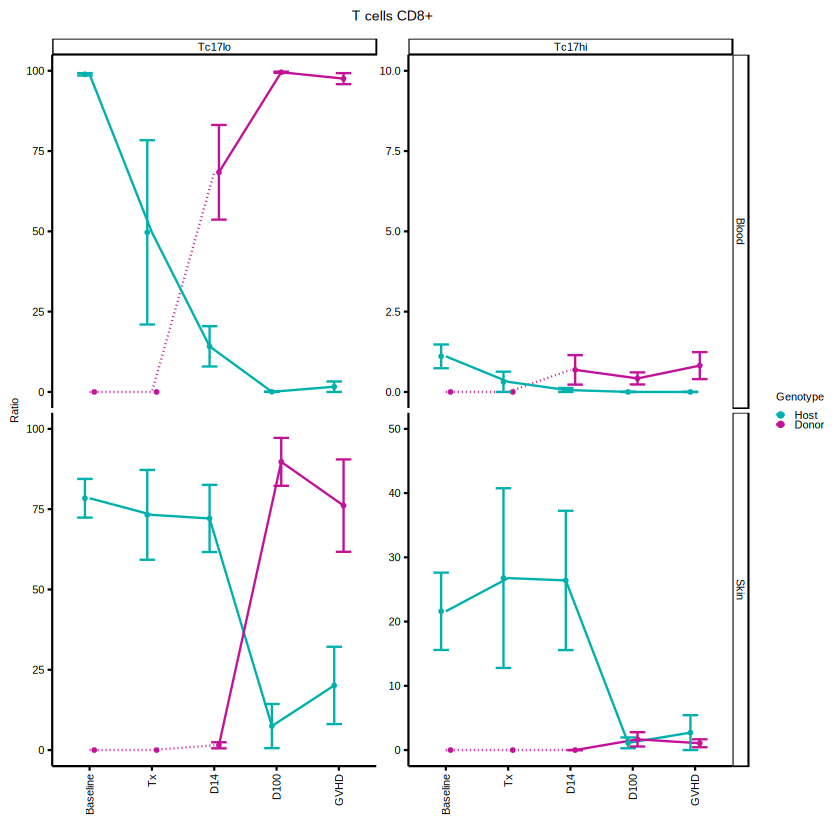

In [180]:
lp

# Differential expression analysis 

In [ ]:
feature_select <- function(so, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE) {
    
    # Select Seurat components 
    meta <- so@meta.data
    cnt <- GetAssayData(so, assay="RNA", slot="counts")
    
    # Prepare data for split 
    cnt <- t(as.matrix(cnt))
    cnt <- as.data.frame(cnt)
    
    # Split expression matrix by grouping variable into list
    cnt <- split(cnt, f=paste(so[[grouping_var, drop=TRUE]], so[[random_effect_var, drop=TRUE]]))
    
    # Check within group expression 
    cnt <- lapply(cnt, function(x) {colSums(x>=cnt_min)>=cell_min})
    cnt <- do.call(rbind, cnt)
    
    # Check across group expression 
    cnt_check <- colSums(cnt)>=feature_group_min
    
    # Get genes 
    genes <- colnames(cnt)[cnt_check]

    # Create Seurat object with gene subset 
    cnt <- GetAssayData(so, assay="RNA", slot="counts")
    cnt <- cnt[genes, , drop=FALSE]

    so <- CreateSeuratObject(counts=cnt, meta=meta)
    
    if(verbose) {message(paste("Final number of genes for testing", nrow(so)))}

    return(so)
    
}

In [ ]:
voom_lm_fit <- function(so, grouping_var, random_effect_var, sample_weights) {

    # Get Counts 
    cnt <- GetAssayData(so, assay="RNA", slot="counts")
    
    # Prepare count data for split 
    cnt <- t(as.matrix(cnt))
    cnt <- as.data.frame(cnt)
    
    # Make pseudobulks by suming single cell counts
    cnt <- split(cnt, f=paste0(so[[grouping_var, drop=TRUE]], "|", so[[random_effect_var, drop=TRUE]]))
    cnt <- lapply(names(cnt), function(i) {x <- data.frame(counts=colSums(cnt[[i]])); colnames(x) <- i; return(x)})
    cnt <- do.call(cbind, cnt)
        
    # Get grouping variables from cnt matrix
    grouping_var_vec <- sapply(strsplit(colnames(cnt), "\\|"), `[[`, 1) # Used for design matrix
    random_effect_var_vec <- sapply(strsplit(colnames(cnt), "\\|"), `[[`, 2) # Used as blocking variable
    
    # Design matrix 
    grouping_var_vec <- as.character(grouping_var_vec)
    design <- model.matrix(~0+grouping_var_vec)
    colnames(design) <- gsub("grouping_var_vec", "", colnames(design))
    
    # Run voomLmFit
    fit <- edgeR::voomLmFit(
        
        counts=cnt, 
        design=design, 
        block=random_effect_var_vec, 
        normalize.method="none", 
        lib.size=NULL, 
        sample.weights=sample_weights, 
        plot=FALSE

    )
    
    return(fit)
    
}

In [ ]:
ebayes <- function(fit, so, grouping_var, grouping_var_vec) {
    
    contrasts_vec <- paste0(grouping_var_vec[1], "-", grouping_var_vec[2])
    contrasts <- limma::makeContrasts(contrasts=contrasts_vec, levels=fit$design)
    contrasts_fit <- limma::contrasts.fit(fit, contrasts=contrasts)
    
    # eBayes fit 
    efit <- limma::eBayes(contrasts_fit)

    # Get result table
    result_df <- limma::topTable(efit, sort.by="P", n=Inf, p.value=1, lfc=0, coef=1)
    
    # Convert results to Seurat format 
    colnames(result_df)[1] <- "avg_log2FC"
    colnames(result_df)[4] <- "p_value"
    colnames(result_df)[5] <- "p_val_adj"

    # Adjusted p-values with IHW
    result_df$p_val_adj <- IHW::adj_pvalues(IHW::ihw(result_df$p_value ~ result_df$AveExpr, alpha=0.05))
            
    # Add percentage expression 
    cnt <- GetAssayData(so, assay="RNA", slot="counts")
    cnt_bool <- cnt[rownames(result_df), ] > 0

    result_df$pct_1<-rowSums(cnt_bool[, so[[grouping_var, drop=TRUE]]==grouping_var_vec[1]])/sum(so[[grouping_var, drop=TRUE]]==grouping_var_vec[1])
    result_df$pct_2<-rowSums(cnt_bool[, so[[grouping_var, drop=TRUE]]==grouping_var_vec[2]])/sum(so[[grouping_var, drop=TRUE]]==grouping_var_vec[2])
    
    return(result_df)
    
}

## Skin T17hi vs Skin T17lo cells 

In [ ]:
grouping_var <- "t_cell_subset"
random_effect_var <- "patient_id"
grouping_var_vec_1 <- c("Th17hi", "Th17lo") %>% make.names()
grouping_var_vec_2 <- c("Tc17hi", "Tc17lo") %>% make.names()
sample_weights <- FALSE

cnt_min=3
cell_min=3
feature_group_min=1

p_adj_thr <- 0.05

so_1 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_1 & hto_demux_class=="Skin")
so_2 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_1 & time_point %in% c("Baseline") & hto_demux_class=="Skin")
so_3 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_1 & time_point %in% c("Tx") & hto_demux_class=="Skin")
so_4 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_1 & time_point %in% c("D14", "D100") & hto_demux_class=="Skin")
so_5 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_1 & time_point %in% c("GVHD") & hto_demux_class=="Skin")

so_6 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_2 & hto_demux_class=="Skin" & hto_demux_class=="Skin")
so_7 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_2 & time_point %in% c("Baseline") & hto_demux_class=="Skin")
so_8 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_2 & time_point %in% c("Tx") & hto_demux_class=="Skin")
so_9 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_2 & time_point %in% c("D14", "D100") & hto_demux_class=="Skin")
so_10 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_2 & time_point %in% c("GVHD") & hto_demux_class=="Skin")

In [ ]:
so_1 <- feature_select(so_1, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_2 <- feature_select(so_2, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_3 <- feature_select(so_3, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_4 <- feature_select(so_4, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_5 <- feature_select(so_5, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_6 <- feature_select(so_6, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_7 <- feature_select(so_7, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_8 <- feature_select(so_8, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_9 <- feature_select(so_9, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_10 <- feature_select(so_10, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)

In [ ]:
fit_1 <- voom_lm_fit(so_1, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_2 <- voom_lm_fit(so_2, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_3 <- voom_lm_fit(so_3, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_4 <- voom_lm_fit(so_4, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_5 <- voom_lm_fit(so_5, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_6 <- voom_lm_fit(so_6, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_7 <- voom_lm_fit(so_7, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_8 <- voom_lm_fit(so_8, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_9 <- voom_lm_fit(so_9, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_10 <- voom_lm_fit(so_10, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)

In [ ]:
result_1 <- ebayes(fit_1, so_1, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_1)
result_2 <- ebayes(fit_2, so_2, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_1)
result_3 <- ebayes(fit_3, so_3, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_1)
result_4 <- ebayes(fit_4, so_4, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_1)
result_5 <- ebayes(fit_5, so_5, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_1)
result_6 <- ebayes(fit_6, so_6, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_2)
result_7 <- ebayes(fit_7, so_7, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_2)
result_8 <- ebayes(fit_8, so_8, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_2)
result_9 <- ebayes(fit_9, so_9, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_2)
result_10 <- ebayes(fit_10, so_10, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_2)

In [ ]:
label_1 <- read.csv("script/figure/figure_3/data/figure_3_dea_trm_cd4pos_subset_skin_selected.csv")$gene
label_2 <- read.csv("script/figure/figure_3/data/figure_3_dea_trm_cd8pos_subset_skin_selected.csv")$gene

In [ ]:
vp_1 <- dea_vp(result_1, title="Th17lo vs Th17hi (ALL)", color_neg=color$t_cell_subset["Th17lo"], color_pos=color$t_cell_subset["Th17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_1)
vp_2 <- dea_vp(result_2, title="Th17lo vs Th17hi (Baseline)", color_neg=color$t_cell_subset["Th17lo"], color_pos=color$t_cell_subset["Th17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_1)
vp_3 <- dea_vp(result_3, title="Th17lo vs Th17hi (Tx)", color_neg=color$t_cell_subset["Th17lo"], color_pos=color$t_cell_subset["Th17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_1)
vp_4 <- dea_vp(result_4, title="Th17lo vs Th17hi (HSCT)", color_neg=color$t_cell_subset["Th17lo"], color_pos=color$t_cell_subset["Th17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_1)
vp_5 <- dea_vp(result_5, title="Th17lo vs Th17hi (GVHD)", color_neg=color$t_cell_subset["Th17lo"], color_pos=color$t_cell_subset["Th17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_1)

vp_6 <- dea_vp(result_6, title="Tc17lo vs Tc17hi (ALL)", color_neg=color$t_cell_subset["Tc17lo"], color_pos=color$t_cell_subset["Tc17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_2)
vp_7 <- dea_vp(result_7, title="Tc17lo vs Tc17hi (Baseline)", color_neg=color$t_cell_subset["Tc17lo"], color_pos=color$t_cell_subset["Tc17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_2)
vp_8 <- dea_vp(result_8, title="Tc17lo vs Tc17hi (Tx)", color_neg=color$t_cell_subset["Tc17lo"], color_pos=color$t_cell_subset["Tc17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_2)
vp_9 <- dea_vp(result_9, title="Tc17lo vs Tc17hi (HSCT)", color_neg=color$t_cell_subset["Tc17lo"], color_pos=color$t_cell_subset["Tc17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_2)
vp_10 <- dea_vp(result_10, title="Tc17lo vs Tc17hi (GVHD)", color_neg=color$t_cell_subset["Tc17lo"], color_pos=color$t_cell_subset["Tc17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_2)

In [ ]:
pdf("result/figures/figure_3/vp_dea_t17_skin.pdf", width=4, height=10)

gridExtra::grid.arrange(

    vp_1 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_6 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_2 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")),
    vp_7 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_3 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_8 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_4 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_9 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_5 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_10 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")),ncol=2

) 

dev.off()

In [ ]:
openxlsx::write.xlsx(list("Th17_ALL"=result_1, "Th17_BASELINE"=result_2, "Th17_TX"=result_3, "Th17_HSCT"=result_4, "Th17_GVHD"=result_5, "Tc17_ALL"=result_6, "Tc17_TX"=result_7, "Tc17_BASELINE"=result_8, "Tc17_HSCT"=result_9, "Tc17_GVHD"=result_10), "result/dea/pseudobulk/t17/t17_skin.xlsx", colNames=TRUE, rowNames=TRUE)

## Blood T17hi vs Blood T17lo cells 

In [ ]:
grouping_var <- "t_cell_subset"
random_effect_var <- "patient_id"
grouping_var_vec_1 <- c("Th17hi", "Th17lo") %>% make.names()
grouping_var_vec_2 <- c("Tc17hi", "Tc17lo") %>% make.names()
sample_weights <- FALSE

cnt_min=3
cell_min=3
feature_group_min=1

p_adj_thr <- 0.05

so_1 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_1 & hto_demux_class=="Blood")
so_2 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_1 & time_point %in% c("Baseline") & hto_demux_class=="Blood")
so_3 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_1 & time_point %in% c("Tx") & hto_demux_class=="Blood")
so_4 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_1 & time_point %in% c("D14", "D100") & hto_demux_class=="Blood")
so_5 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_1 & time_point %in% c("GVHD") & hto_demux_class=="Blood")

so_6 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_2 & hto_demux_class=="Blood" & hto_demux_class=="Blood")
so_7 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_2 & time_point %in% c("Baseline") & hto_demux_class=="Blood")
so_8 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_2 & time_point %in% c("Tx") & hto_demux_class=="Blood")
so_9 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_2 & time_point %in% c("D14", "D100") & hto_demux_class=="Blood")
so_10 <- subset(so, subset=t_cell_subset %in% grouping_var_vec_2 & time_point %in% c("GVHD") & hto_demux_class=="Blood")

In [ ]:
so_1 <- feature_select(so_1, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_2 <- feature_select(so_2, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_3 <- feature_select(so_3, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_4 <- feature_select(so_4, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_5 <- feature_select(so_5, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_6 <- feature_select(so_6, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_7 <- feature_select(so_7, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_8 <- feature_select(so_8, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_9 <- feature_select(so_9, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)
so_10 <- feature_select(so_10, cnt_min, cell_min, grouping_var, random_effect_var, feature_group_min, verbose=TRUE)

In [ ]:
fit_1 <- voom_lm_fit(so_1, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_2 <- voom_lm_fit(so_2, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_3 <- voom_lm_fit(so_3, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_4 <- voom_lm_fit(so_4, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_5 <- voom_lm_fit(so_5, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_6 <- voom_lm_fit(so_6, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_7 <- voom_lm_fit(so_7, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_8 <- voom_lm_fit(so_8, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_9 <- voom_lm_fit(so_9, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)
fit_10 <- voom_lm_fit(so_10, grouping_var=grouping_var, random_effect_var=random_effect_var, sample_weights=sample_weights)

In [ ]:
result_1 <- ebayes(fit_1, so_1, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_1)
result_2 <- ebayes(fit_2, so_2, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_1)
result_3 <- ebayes(fit_3, so_3, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_1)
result_4 <- ebayes(fit_4, so_4, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_1)
result_5 <- ebayes(fit_5, so_5, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_1)
result_6 <- ebayes(fit_6, so_6, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_2)
result_7 <- ebayes(fit_7, so_7, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_2)
result_8 <- ebayes(fit_8, so_8, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_2)
result_9 <- ebayes(fit_9, so_9, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_2)
result_10 <- ebayes(fit_10, so_10, grouping_var=grouping_var, grouping_var_vec=grouping_var_vec_2)

In [ ]:
label_1 <- read.csv("script/figure/figure_3/data/figure_3_dea_trm_cd4pos_subset_skin_selected.csv")$gene
label_2 <- read.csv("script/figure/figure_3/data/figure_3_dea_trm_cd8pos_subset_skin_selected.csv")$gene

In [ ]:
vp_1 <- dea_vp(result_1, title="Th17lo vs Th17hi (ALL)", color_neg=color$t_cell_subset["Th17lo"], color_pos=color$t_cell_subset["Th17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_1)
vp_2 <- dea_vp(result_2, title="Th17lo vs Th17hi (Baseline)", color_neg=color$t_cell_subset["Th17lo"], color_pos=color$t_cell_subset["Th17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_1)
vp_3 <- dea_vp(result_3, title="Th17lo vs Th17hi (Tx)", color_neg=color$t_cell_subset["Th17lo"], color_pos=color$t_cell_subset["Th17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_1)
vp_4 <- dea_vp(result_4, title="Th17lo vs Th17hi (HSCT)", color_neg=color$t_cell_subset["Th17lo"], color_pos=color$t_cell_subset["Th17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_1)
vp_5 <- dea_vp(result_5, title="Th17lo vs Th17hi (GVHD)", color_neg=color$t_cell_subset["Th17lo"], color_pos=color$t_cell_subset["Th17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_1)

vp_6 <- dea_vp(result_6, title="Tc17lo vs Tc17hi (ALL)", color_neg=color$t_cell_subset["Tc17lo"], color_pos=color$t_cell_subset["Tc17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_2)
vp_7 <- dea_vp(result_7, title="Tc17lo vs Tc17hi (Baseline)", color_neg=color$t_cell_subset["Tc17lo"], color_pos=color$t_cell_subset["Tc17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_2)
vp_8 <- dea_vp(result_8, title="Tc17lo vs Tc17hi (Tx)", color_neg=color$t_cell_subset["Tc17lo"], color_pos=color$t_cell_subset["Tc17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_2)
vp_9 <- dea_vp(result_9, title="Tc17lo vs Tc17hi (HSCT)", color_neg=color$t_cell_subset["Tc17lo"], color_pos=color$t_cell_subset["Tc17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_2)
vp_10 <- dea_vp(result_10, title="Tc17lo vs Tc17hi (GVHD)", color_neg=color$t_cell_subset["Tc17lo"], color_pos=color$t_cell_subset["Tc17hi"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_2)

In [ ]:
pdf("result/figures/figure_3/vp_dea_t17_blood.pdf", width=4, height=10)

gridExtra::grid.arrange(

    vp_1 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_6 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_2 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")),
    vp_7 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_3 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_8 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_4 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_9 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_5 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_10 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")),ncol=2

) 

dev.off()

In [ ]:
openxlsx::write.xlsx(list("Th17_ALL"=result_1, "Th17_BASELINE"=result_2, "Th17_TX"=result_3, "Th17_HSCT"=result_4, "Th17_GVHD"=result_5, "Tc17_ALL"=result_6, "Tc17_TX"=result_7, "Tc17_BASELINE"=result_8, "Tc17_HSCT"=result_9, "Tc17_GVHD"=result_10), "result/dea/pseudobulk/t17/t17_blood.xlsx", colNames=TRUE, rowNames=TRUE)

## Skin Th17hi HSCT host vs donor

In [ ]:
p_adj_thr <- 0.05

In [ ]:
result_1 <- readRDS("result/dea/pseudobulk/genotype/celltype_low/results_skin_hsct.rds")[['T[\'h\']*\' RM\'']][["Donor-Host"]]
result_2 <- readRDS("result/dea/pseudobulk/genotype/celltype_low/results_skin_gvhd.rds")[['T[\'h\']*\' RM\'']][["Donor-Host"]]
result_3 <- readRDS("result/dea/pseudobulk/genotype/celltype_low/results_skin_hsct.rds")[['T[\'c\']*\' RM\'']][["Donor-Host"]]
result_4 <- readRDS("result/dea/pseudobulk/genotype/celltype_low/results_skin_gvhd.rds")[['T[\'c\']*\' RM\'']][["Donor-Host"]]

In [ ]:
label_1 <- read.csv("script/figure/figure_3/data/figure_3_dea_genotype_ThRM_HSCT_selected.csv")$gene
label_2 <- read.csv("script/figure/figure_3/data/figure_3_dea_genotype_ThRM_HSCT_selected.csv")$gene
label_3 <- read.csv("script/figure/figure_3/data/figure_3_dea_genotype_TcRM_HSCT_selected.csv")$gene
label_4 <- read.csv("script/figure/figure_3/data/figure_3_dea_genotype_TcRM_GVHD_selected.csv")$gene

In [ ]:
vp_1 <- dea_vp(result_1, title="HSCT CD4+ Skin", color_neg=color$genotype_class["Host"], color_pos=color$genotype_class["Donor"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_1)
vp_2 <- dea_vp(result_2, title="GVHD CD4+ Skin", color_neg=color$genotype_class["Host"], color_pos=color$genotype_class["Donor"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_2)
vp_3 <- dea_vp(result_3, title="HSCT CD8+ Skin", color_neg=color$genotype_class["Host"], color_pos=color$genotype_class["Donor"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_3)
vp_4 <- dea_vp(result_4, title="GVHD CD8+ Skin", color_neg=color$genotype_class["Host"], color_pos=color$genotype_class["Donor"], log2fc_thr=0, p_adj_thr=p_adj_thr, top_label=20, parse_title=FALSE, label=label_4)

In [ ]:
pdf("result/figures/figure_3/vp_dea_t17_skin_genotype.pdf", width=8, height=2)

gridExtra::grid.arrange(

    vp_1 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_2 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")), 
    vp_3 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")),
    vp_4 %>% egg::set_panel_size(., width=unit(3, "cm"), height=unit(3, "cm")),ncol=4

) 

dev.off()

# Gene regulatory network analysis 

## Time points

In [ ]:
contrasts_vec <- list(
    
    c("GVHD", "Baseline")
    
)

In [ ]:
res <- lapply(contrasts_vec, function(i) {

    res_i <- readRDS(paste0("result/scenic/wilcox/", "auc_", tolower(i[1]), "_vs_", tolower(i[2]), ".rds"))
    res_i <- do.call("rbind", res_i)
    res_i$contrast <- i[1]

    return(res_i)
    
}
      )

In [ ]:
res <- lapply(res, function(x) {x %>% dplyr::filter(celltype_low %in% c("T['h']*' E/EM'", "T['c']*' E/EM'", "T['h']*' RM'", "T['c']*' RM'")) %>% droplevels()})

In [ ]:
res <- do.call("rbind", res)
rownames(res) <- NULL
res <- split(res, f=res$celltype_low)

In [ ]:
pdf("result/figures/figure_3/hm_grn_t_cell_time_points.pdf", width=20, height=5)

hm_grn_res <- lapply(names(res), function(i) {hm_grn(res[[i]], column_title=i, fontsize_select=2, p_val_adj_thr=0.05, avg_log2FC_thr=0, rank_thr=Inf, top_thr=20, cluster_columns=FALSE)})
hm_grn_res <- Reduce(`+`, hm_grn_res)
draw(hm_grn_res)

dev.off()

# T cell type 17

In [ ]:
contrasts_vec <- list(

    c("Th17hi", "Th17lo"), 
    c("Tc17hi", "Tc17lo")
    
)

In [ ]:
res <- lapply(contrasts_vec, function(i) {

    res_i <- readRDS(paste0("result/scenic//wilcox/", "auc_", tolower(i[1]), "_vs_", tolower(i[2]), ".rds"))
    res_i <- do.call("rbind", res_i)
    res_i$contrast <- i[1]

    return(res_i)
    
}
      )

In [ ]:
res <- do.call("rbind", res) %>% droplevels()
rownames(res) <- NULL
res <- split(res, f=res$celltype_low)

In [ ]:
names(res) <- c("Th17~Skin", "Th17~Blood", "Tc17~Skin", "Tc17~Blood")

In [ ]:
pdf("result/figures/figure_3/hm_grn_t_cell_type_17.pdf", width=20, height=5)

source("bin/grn_pl.R")

hm_grn_res <- lapply(names(res), function(i) {hm_grn(res[[i]], column_title=i, fontsize_select=2, p_val_adj_thr=0.05, avg_log2FC_thr=0, rank_thr=Inf, top_thr=20, cluster_columns=FALSE)})
hm_grn_res <- Reduce(`+`, hm_grn_res)
draw(hm_grn_res)

dev.off()